# Personalized Learning Recommendation System

## Project Overview

This project develops a Personalized Learning Recommendation System
using the Open University Learning Analytics Dataset (OULAD).

The system analyzes a learner's historical interaction behaviour,
academic activity, and learning resource characteristics to recommend
new learning resources.

### Main Pipeline

Dataset
→ Data Understanding
→ Data Cleaning
→ Exploratory Data Analysis
→ Feature Engineering
→ Temporal Split
→ Candidate Generation
→ Machine Learning
→ Recommendation Ranking
→ Evaluation

## 1. Project Objective

The objective of this project is to recommend suitable learning
resources to learners based on their observed learning behaviour
and available academic information.

The system follows these main steps:

1. Analyze learner interaction history.
2. Identify resources already explored by the learner.
3. Generate unseen candidate resources from the same course.
4. Create learner-resource features.
5. Train a supervised Machine Learning model.
6. Rank candidate resources using the model score.
7. Return the Top-K recommendations.
8. Evaluate the recommendation quality using ranking metrics.

## 2. Dataset

The project uses the Open University Learning Analytics Dataset (OULAD).

The dataset contains information about:

- Students
- Courses and course presentations
- Assessments
- Assessment results
- Virtual Learning Environment (VLE) resources
- Student-resource interactions

The VLE interaction data records how learners interacted with
learning resources over time.

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

import warnings

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Load the Dataset

We first load the main OULAD files required for understanding
students, assessments, learning resources, and learner interactions.

In [5]:
DATA_PATH = "../dataset/raw/"

student_info = pd.read_csv(
    DATA_PATH + "studentInfo.csv"
)

assessments = pd.read_csv(
    DATA_PATH + "assessments.csv"
)

student_assessment = pd.read_csv(
    DATA_PATH + "studentAssessment.csv"
)

vle = pd.read_csv(
    DATA_PATH + "vle.csv"
)

student_registration = pd.read_csv(
    DATA_PATH + "studentRegistration.csv"
)

courses = pd.read_csv(
    DATA_PATH + "courses.csv"
)

print("Dataset files loaded successfully.")

Dataset files loaded successfully.


In [6]:
print("Student Information:", student_info.shape)
print("Assessments:", assessments.shape)
print("Student Assessment:", student_assessment.shape)
print("VLE Resources:", vle.shape)
print("Student Registration:", student_registration.shape)
print("Courses:", courses.shape)

Student Information: (32593, 12)
Assessments: (206, 6)
Student Assessment: (173912, 5)
VLE Resources: (6364, 6)
Student Registration: (32593, 5)
Courses: (22, 3)


## 4. Dataset Structure

Before building the recommendation system, we inspect the columns
available in each dataset.

This helps us understand which variables can be used for learner
behaviour, academic performance, and resource-level information.

In [9]:
print("Student Information Columns:")
print(student_info.columns.tolist())

print("\nAssessment Columns:")
print(student_assessment.columns.tolist())

print("\nVLE Columns:")
print(vle.columns.tolist())

Student Information Columns:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

Assessment Columns:
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

VLE Columns:
['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


## 5. Preview the Data

We inspect a few rows from the student and VLE datasets to understand
the structure of the raw records.

In [10]:
display(student_info.head())

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [11]:
display(vle.head())

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?


## 6. Basic Data Quality Check

We check for missing values in the main datasets.

Missing values are important because they may affect feature
engineering and Machine Learning preprocessing.

In [12]:
print("Missing values in Student Information:")
display(student_info.isnull().sum())

print("Missing values in Assessments:")
display(assessments.isnull().sum())

print("Missing values in VLE:")
display(vle.isnull().sum())

Missing values in Student Information:


code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
dtype: int64

Missing values in Assessments:


code_module          0
code_presentation    0
id_assessment        0
assessment_type      0
date                 0
weight               0
dtype: int64

Missing values in VLE:


id_site              0
code_module          0
code_presentation    0
activity_type        0
week_from            0
week_to              0
dtype: int64

### Important Data Handling Decision

Missing assessment scores are not automatically treated as zero.

A missing score does not necessarily mean that the learner received
zero marks. Therefore, missing numerical values are handled later
during the Machine Learning preprocessing stage using imputation.

# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand:

- Learner performance
- Learning interaction behaviour
- Available resource types
- Relationship between interactions and assessment performance

The visualizations below are based on the observed dataset.

## 7.1 Distribution of Assessment Scores

The assessment score distribution shows how learner performance
is distributed across the dataset.

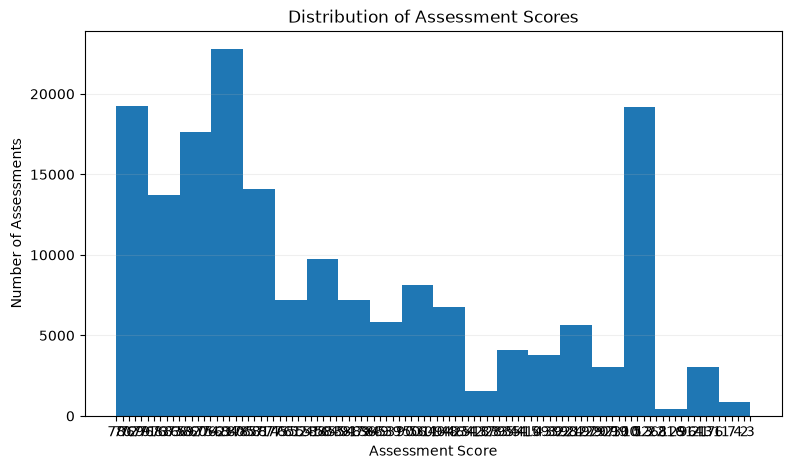

In [13]:
score_data = student_assessment["score"].dropna()

plt.figure(figsize=(9, 5))

plt.hist(
    score_data,
    bins=20
)

plt.title("Distribution of Assessment Scores")
plt.xlabel("Assessment Score")
plt.ylabel("Number of Assessments")

plt.grid(axis="y", alpha=0.2)

plt.show()

## 7.2 Learning Resource Activity Types

The VLE dataset contains different types of learning resources,
such as resources, subpages, content pages, URLs, forums and quizzes.

We analyze their distribution to understand the learning resource
ecosystem.

In [14]:
activity_counts = (
    vle["activity_type"]
    .value_counts()
)

display(activity_counts.head(10))

activity_type
resource         2660
subpage          1055
oucontent         996
url               886
forumng           194
quiz              127
page              102
oucollaborate      82
questionnaire      61
ouwiki             49
Name: count, dtype: int64

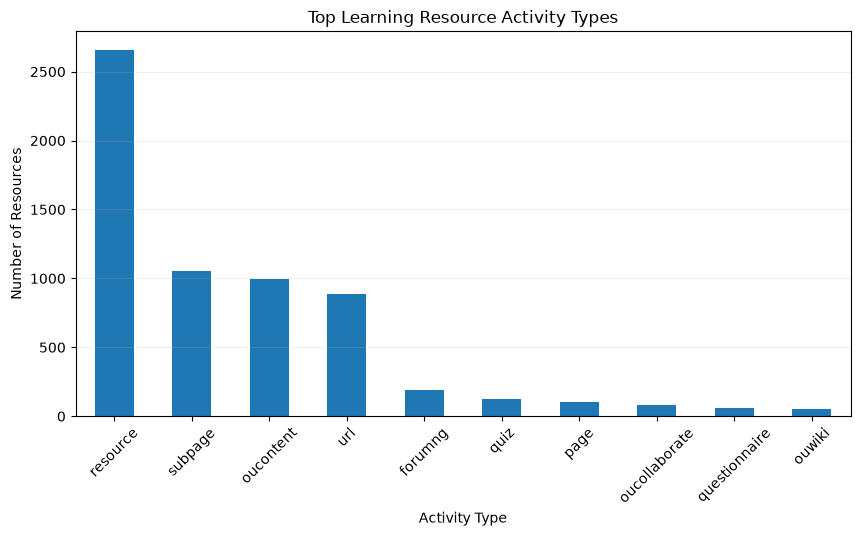

In [15]:
plt.figure(figsize=(10, 5))

activity_counts.head(10).plot(
    kind="bar"
)

plt.title("Top Learning Resource Activity Types")
plt.xlabel("Activity Type")
plt.ylabel("Number of Resources")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.2)

plt.show()

## 7.3 Course-wise Resource Distribution

Different courses contain different numbers of learning resources.

We calculate the number of resources available for each course
presentation.

In [16]:
course_resources = (
    vle
    .groupby([
        "code_module",
        "code_presentation"
    ])
    .size()
    .reset_index(name="resource_count")
)

display(
    course_resources.sort_values(
        "resource_count",
        ascending=False
    ).head(10)
)

,code_module,code_presentation,resource_count
16,FFF,2013J,529
15,FFF,2013B,508
17,FFF,2014B,478
9,DDD,2013J,462
10,DDD,2014B,453
18,FFF,2014J,452
8,DDD,2013B,428
11,DDD,2014J,365
3,BBB,2013J,321
2,BBB,2013B,315


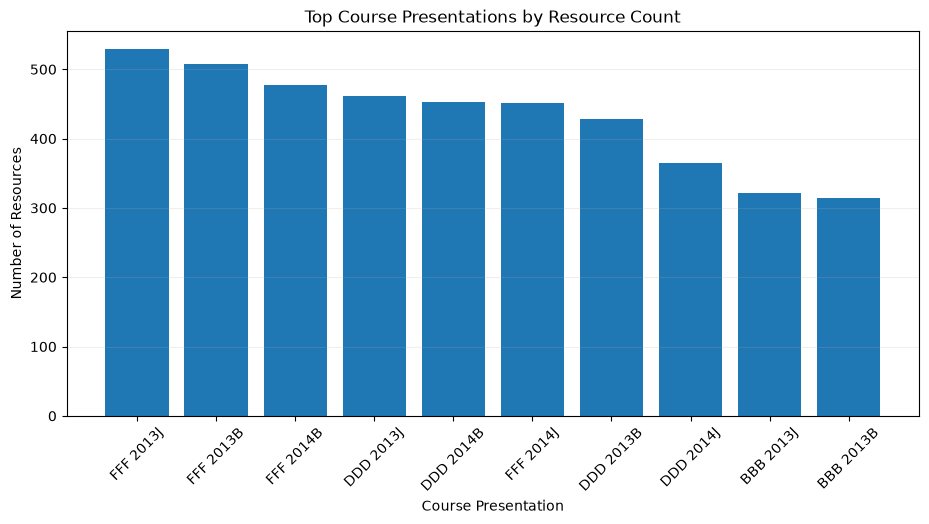

In [17]:
top_courses = (
    course_resources
    .sort_values(
        "resource_count",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(11, 5))

labels = (
    top_courses["code_module"]
    + " "
    + top_courses["code_presentation"]
)

plt.bar(
    labels,
    top_courses["resource_count"]
)

plt.title("Top Course Presentations by Resource Count")
plt.xlabel("Course Presentation")
plt.ylabel("Number of Resources")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.2)

plt.show()

## 8. Student Learning Interaction Data

The `studentVle.csv` file records learner interactions with
Virtual Learning Environment resources.

Important columns include:

- `id_student` — learner identifier
- `id_site` — learning resource identifier
- `code_module` — course
- `code_presentation` — course presentation
- `date` — interaction day
- `sum_click` — number of clicks/interactions

This file is large, so it is processed in chunks to reduce memory usage.

In [18]:
STUDENT_VLE_PATH = "../dataset/raw/studentVle.csv"

chunk_size = 500_000

processed_chunks = []

for chunk in pd.read_csv(
    STUDENT_VLE_PATH,
    chunksize=chunk_size
):

    grouped_chunk = (
        chunk
        .groupby([
            "id_student",
            "id_site",
            "code_module",
            "code_presentation",
            "date"
        ])["sum_click"]
        .sum()
        .reset_index()
    )

    processed_chunks.append(grouped_chunk)

print("Chunks processed:", len(processed_chunks))

Chunks processed: 22


### Combining the Processed Chunks

Each chunk is aggregated separately.

After processing all chunks, we combine them and perform one final
grouping to make sure duplicate interaction keys across chunk
boundaries are also aggregated correctly.

In [19]:
student_vle_processed = pd.concat(
    processed_chunks,
    ignore_index=True
)

student_vle_processed.shape

(8459345, 6)

In [20]:
student_vle_processed = (
    student_vle_processed
    .groupby([
        "id_student",
        "id_site",
        "code_module",
        "code_presentation",
        "date"
    ])["sum_click"]
    .sum()
    .reset_index()
)

print(
    "Processed interaction rows:",
    len(student_vle_processed)
)


Processed interaction rows: 8459320


## 9. Validate the Interaction Dataset

We validate the processed interaction data by checking:

1. Number of rows
2. Duplicate interaction keys
3. Missing values
4. Data types

In [21]:
interaction_keys = [
    "id_student",
    "id_site",
    "code_module",
    "code_presentation",
    "date"
]

duplicate_count = (
    student_vle_processed
    .duplicated(interaction_keys)
    .sum()
)

print("Total rows:", len(student_vle_processed))
print("Duplicate interaction keys:", duplicate_count)
print("\nMissing values:")
print(student_vle_processed.isnull().sum())

Total rows: 8459320
Duplicate interaction keys: 0

Missing values:
id_student           0
id_site              0
code_module          0
code_presentation    0
date                 0
sum_click            0
dtype: int64


## 10. Connect Interactions with Resource Information

The interaction dataset contains the resource ID (`id_site`),
while the VLE dataset contains information about the resource,
including its activity type.

We merge both datasets using `id_site` so that each learner
interaction can be associated with a resource type.

In [22]:
vle_lookup = (
    vle[
        [
            "id_site",
            "code_module",
            "code_presentation",
            "activity_type"
        ]
    ]
    .drop_duplicates()
)

student_resource_interactions = (
    student_vle_processed
    .merge(
        vle_lookup,
        on=[
            "id_site",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )
)

print(
    "Final interaction dataset shape:",
    student_resource_interactions.shape
)

Final interaction dataset shape: (8459320, 7)


In [23]:
print(
    "Missing activity types:",
    student_resource_interactions["activity_type"]
    .isna()
    .sum()
)

display(
    student_resource_interactions.head()
)

Missing activity types: 0


,id_student,id_site,code_module,code_presentation,date,sum_click,activity_type
0,6516,877011,AAA,2014J,204,6,forumng
1,6516,877011,AAA,2014J,209,8,forumng
2,6516,877011,AAA,2014J,218,9,forumng
3,6516,877012,AAA,2014J,0,38,forumng
4,6516,877012,AAA,2014J,5,12,forumng


## 11. Learner-Level Interaction Features

Raw interaction records are not directly suitable as learner-level
features.

Therefore, we aggregate the interaction history for each learner
within each course presentation.

The following behavioural features are created:

- Total interactions
- Unique resources explored
- First activity day
- Last activity day
- Number of active days
- Learning span
- Average interactions per active day

In [24]:
learner_features = (
    student_resource_interactions
    .groupby([
        "id_student",
        "code_module",
        "code_presentation"
    ])
    .agg(
        total_clicks=("sum_click", "sum"),
        unique_resources=("id_site", "nunique"),
        first_activity_day=("date", "min"),
        last_activity_day=("date", "max"),
        active_days=("date", "nunique")
    )
    .reset_index()
)

learner_features["learning_span_days"] = (
    learner_features["last_activity_day"]
    - learner_features["first_activity_day"]
)

learner_features["avg_clicks_per_active_day"] = (
    learner_features["total_clicks"]
    /
    learner_features["active_days"].replace(0, np.nan)
)

display(learner_features.head())

,id_student,code_module,code_presentation,total_clicks,unique_resources,first_activity_day,last_activity_day,active_days,learning_span_days,avg_clicks_per_active_day
0,6516,AAA,2014J,2791,84,-23,269,159,292,17.553459
1,8462,DDD,2013J,646,125,-6,118,56,124,11.535714
2,8462,DDD,2014J,10,3,10,10,1,0,10.000000
3,11391,AAA,2013J,934,55,-5,253,40,258,23.350000
4,23629,BBB,2013B,161,11,-6,87,16,93,10.062500


### Interpretation

These features summarize how actively and consistently a learner
used the learning platform.

For example:

- `total_clicks` represents total recorded interactions.
- `unique_resources` represents the number of different resources explored.
- `active_days` represents the number of days with recorded activity.
- `learning_span_days` represents the time between first and last activity.
- `avg_clicks_per_active_day` represents average interaction intensity.

In [25]:
learner_features[
    [
        "total_clicks",
        "unique_resources",
        "active_days",
        "learning_span_days",
        "avg_clicks_per_active_day"
    ]
].describe()

,total_clicks,unique_resources,active_days,learning_span_days,avg_clicks_per_active_day
count,29228.000000,29228.000000,29228.000000,29228.000000,29228.000000
mean,1355.039654,67.075955,61.862563,185.518578,19.042236
std,1733.546045,54.953382,54.027412,92.447016,11.576835
min,1.000000,1.000000,1.000000,0.000000,1.000000
25%,260.750000,27.000000,18.000000,104.000000,11.207887
50%,739.500000,51.000000,47.000000,234.000000,16.360556
75%,1770.000000,93.000000,92.000000,256.000000,24.412698
max,24139.000000,413.000000,286.000000,293.000000,221.200000


## 12. Learning Interaction vs Academic Performance

We now investigate whether learner interaction behaviour has any
observable relationship with assessment performance.

This is an exploratory analysis only.

A correlation does not imply that higher interaction causes
higher academic performance.

In [28]:
print(student_assessment["score"].dtype)

print(
    student_assessment["score"]
    .head(20)
)

print(
    student_assessment["score"]
    .apply(type)
    .value_counts()
)

str
0     78
1     70
2     72
3     69
4     79
5     70
6     72
7     72
8     71
9     68
10    73
11    67
12    73
13    83
14    66
15    59
16    82
17    60
18    67
19    73
Name: score, dtype: str
score
<class 'str'>    173912
Name: count, dtype: int64


In [29]:
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

print(
    student_assessment["score"].dtype
)

print(
    "Missing scores:",
    student_assessment["score"].isna().sum()
)

float64
Missing scores: 173


### Handling Assessment Scores

The assessment score column is converted to a numeric data type before
calculating learner-level statistics.

Invalid or missing score values are converted to `NaN` rather than
zero, because a missing score does not necessarily represent a score
of zero.

The missing values are handled later during the Machine Learning
preprocessing stage.

In [30]:
student_performance = (
    student_assessment
    .groupby("id_student")
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max")
    )
    .reset_index()
)

display(student_performance.head())

,id_student,average_score,assessment_count,min_score,max_score
0,6516,61.800000,5,48.0,77.0
1,8462,87.000000,7,83.0,93.0
2,11391,82.000000,5,78.0,85.0
3,23629,82.500000,4,63.0,100.0
4,23698,74.444444,9,56.0,94.0


In [31]:
learner_overall = (
    learner_features
    .groupby("id_student")
    .agg(
        total_clicks=("total_clicks", "sum"),
        unique_resources=("unique_resources", "sum"),
        active_days=("active_days", "sum")
    )
    .reset_index()
)

learner_performance = (
    learner_overall
    .merge(
        student_performance,
        on="id_student",
        how="inner"
    )
)

print(
    "Learners available for analysis:",
    len(learner_performance)
)

display(learner_performance.head())

Learners available for analysis: 23344


,id_student,total_clicks,unique_resources,active_days,average_score,assessment_count,min_score,max_score
0,6516,2791,84,159,61.800000,5,48.0,77.0
1,8462,656,128,57,87.000000,7,83.0,93.0
2,11391,934,55,40,82.000000,5,78.0,85.0
3,23629,161,11,16,82.500000,4,63.0,100.0
4,23698,910,49,70,74.444444,9,56.0,94.0


## 13. Correlation Analysis

We calculate the correlation between total learning interactions
and average assessment score.

The purpose is to understand whether the two variables show an
observable linear relationship in the dataset.

In [32]:
correlation = (
    learner_performance[
        ["total_clicks", "average_score"]
    ]
    .corr()
)

display(correlation)


,total_clicks,average_score
total_clicks,1.000000,0.274139
average_score,0.274139,1.000000


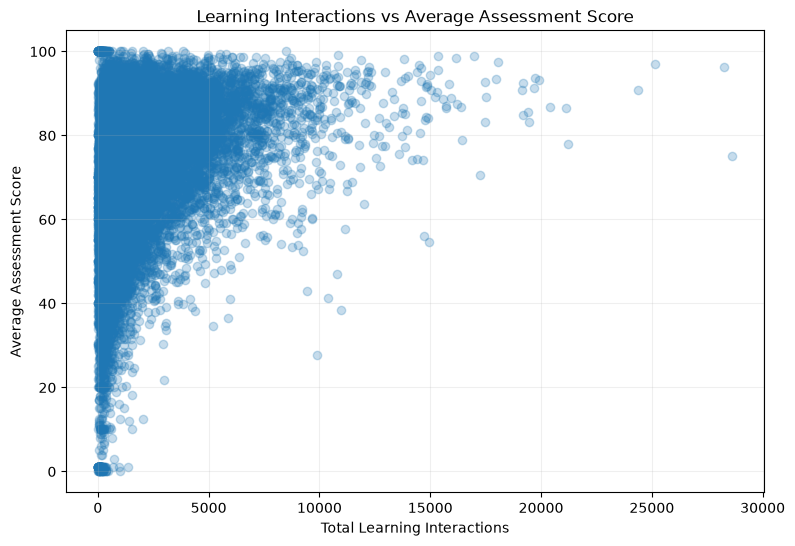

In [33]:
plot_data = learner_performance.dropna(
    subset=[
        "total_clicks",
        "average_score"
    ]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_data["total_clicks"],
    plot_data["average_score"],
    alpha=0.25
)

plt.title(
    "Learning Interactions vs Average Assessment Score"
)

plt.xlabel("Total Learning Interactions")
plt.ylabel("Average Assessment Score")

plt.grid(alpha=0.2)

plt.show()

### Observation

The scatter plot shows the relationship between learner interaction
volume and average assessment performance.

The relationship is positive but not strong, indicating that interaction
volume alone is not sufficient to explain learner performance.

Therefore, the recommendation system uses multiple behavioural,
academic, and resource-level features rather than relying only on
total clicks.

# 14. Resource-Level Interaction Behaviour

Learners interact with different types of learning resources.

We calculate the interaction distribution across activity types
to understand the learner's observed interaction pattern.

These interaction shares are treated as observed behaviour,
not explicit learner preferences.

In [34]:
activity_interactions = (
    student_resource_interactions
    .groupby("activity_type")["sum_click"]
    .sum()
    .sort_values(ascending=False)
)

display(
    activity_interactions.head(10)
)

activity_type
oucontent        11206803
forumng           7973390
quiz              6981240
homepage          6949064
subpage           3411582
resource          1110132
ouwiki             894512
url                566702
oucollaborate      108974
glossary            87962
Name: sum_click, dtype: int64

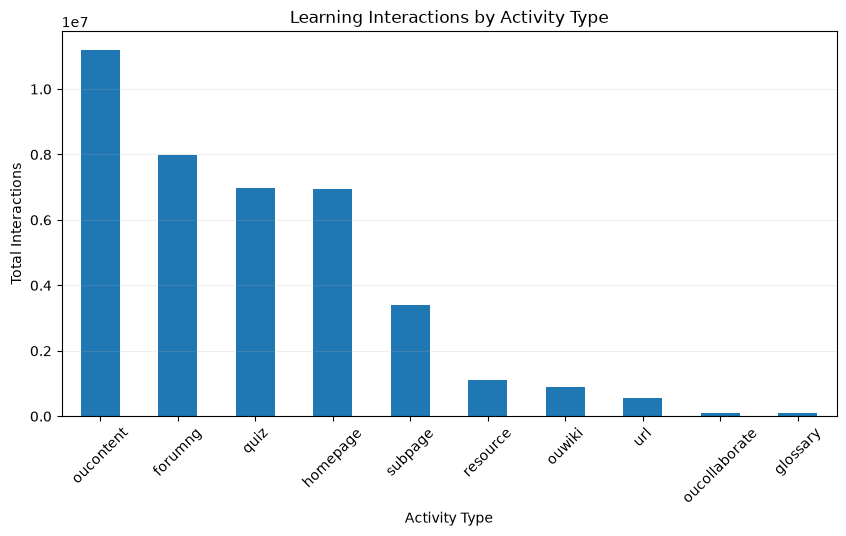

In [35]:
plt.figure(figsize=(10, 5))

activity_interactions.head(10).plot(
    kind="bar"
)

plt.title(
    "Learning Interactions by Activity Type"
)

plt.xlabel("Activity Type")
plt.ylabel("Total Interactions")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.2)

plt.show()

# 15. Temporal Recommendation Setup

A recommendation system should use past learner behaviour to predict
future learning behaviour.

Therefore, instead of randomly splitting the interaction data, we use
a temporal split.

For each learner-course-presentation combination:

- The earlier 80% of the learning timeline is treated as history.
- The later 20% is treated as future behaviour.
- Future resources that were not present in the learner's history
  become the ground-truth recommendation targets.

This helps prevent future information from leaking into the learner's
historical features.

## 15.1 Prepare Interaction Dates

The interaction data contains the day on which each learner interacted
with a resource.

We first calculate the first and last observed interaction for each
learner within each course presentation.

In [36]:
course_time = (
    student_resource_interactions
    .groupby([
        "id_student",
        "code_module",
        "code_presentation"
    ])["date"]
    .agg(["min", "max"])
    .reset_index()
)

course_time["span"] = (
    course_time["max"]
    - course_time["min"]
)

course_time["cutoff"] = (
    course_time["min"]
    + 0.8 * course_time["span"]
)

display(course_time.head())

,id_student,code_module,code_presentation,min,max,span,cutoff
0,6516,AAA,2014J,-23,269,292,210.6
1,8462,DDD,2013J,-6,118,124,93.2
2,8462,DDD,2014J,10,10,0,10.0
3,11391,AAA,2013J,-5,253,258,201.4
4,23629,BBB,2013B,-6,87,93,68.4


In [37]:
print("Total learner-course profiles:", len(course_time))

print(
    "Average learning span:",
    course_time["span"].mean()
)

display(
    course_time["span"].describe()
)

Total learner-course profiles: 29228
Average learning span: 185.51857807581771


count    29228.000000
mean       185.518578
std         92.447016
min          0.000000
25%        104.000000
50%        234.000000
75%        256.000000
max        293.000000
Name: span, dtype: float64

## 15.2 Create Historical and Future Interactions

The cutoff date divides each learner's timeline into two parts.

History:
Interactions occurring on or before the cutoff.

Future:
Interactions occurring after the cutoff.

The history is used to construct the learner profile, while future
interactions are used only for evaluation.

In [38]:
history_interactions = (
    student_resource_interactions
    .merge(
        course_time[
            [
                "id_student",
                "code_module",
                "code_presentation",
                "cutoff"
            ]
        ],
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="inner"
    )
)

history_interactions = history_interactions[
    history_interactions["date"]
    <= history_interactions["cutoff"]
].copy()


future_interactions = (
    student_resource_interactions
    .merge(
        course_time[
            [
                "id_student",
                "code_module",
                "code_presentation",
                "cutoff"
            ]
        ],
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="inner"
    )
)

future_interactions = future_interactions[
    future_interactions["date"]
    > future_interactions["cutoff"]
].copy()

In [39]:
print("History interactions:", len(history_interactions))
print("Future interactions:", len(future_interactions))

History interactions: 7107016
Future interactions: 1352304


## 15.3 Compare the Temporal Split

The temporal split allows us to verify that the majority of learner
activity is represented by historical interactions, while later
interactions are reserved for future evaluation.

In [40]:
split_counts = pd.DataFrame({
    "Interaction Set": [
        "History",
        "Future"
    ],
    "Rows": [
        len(history_interactions),
        len(future_interactions)
    ]
})

display(split_counts)

,Interaction Set,Rows
0,History,7107016
1,Future,1352304


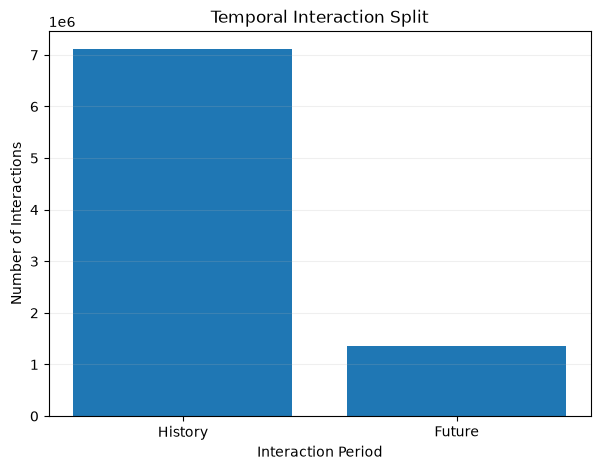

In [41]:
plt.figure(figsize=(7, 5))

plt.bar(
    split_counts["Interaction Set"],
    split_counts["Rows"]
)

plt.title("Temporal Interaction Split")
plt.xlabel("Interaction Period")
plt.ylabel("Number of Interactions")

plt.grid(axis="y", alpha=0.2)

plt.show()

## 16. Ground-Truth Recommendation Targets

For each learner-course-presentation profile, we compare the resources
seen in the historical period with resources appearing in the future.

A resource is considered a positive recommendation target when:

1. It appears in the future period.
2. It was not already present in the historical period.

These are called future unseen resources.

In [42]:
history_resources = (
    history_interactions
    .groupby([
        "id_student",
        "code_module",
        "code_presentation"
    ])["id_site"]
    .agg(set)
    .reset_index(name="history_resources")
)

display(history_resources.head())

,id_student,code_module,code_presentation,history_resources
0,6516,AAA,2014J,"{877056, 877058, 877059, 877061, 877062, 87706..."
1,8462,DDD,2013J,"{674306, 674314, 674322, 674325, 674332, 67434..."
2,8462,DDD,2014J,"{814280, 813701, 813710}"
3,11391,AAA,2013J,"{546688, 546691, 546692, 546694, 546702, 54671..."
4,23629,BBB,2013B,"{543113, 542891, 542892, 542797, 543055, 54286..."


In [43]:
future_resources = (
    future_interactions
    .groupby([
        "id_student",
        "code_module",
        "code_presentation"
    ])["id_site"]
    .agg(set)
    .reset_index(name="future_resources")
)

display(future_resources.head())

,id_student,code_module,code_presentation,future_resources
0,6516,AAA,2014J,"{877059, 877061, 877064, 877067, 877074, 87708..."
1,8462,DDD,2013J,"{674433, 674057, 673519, 674257, 674099, 67416..."
2,11391,AAA,2013J,"{546691, 546692, 546694, 546696, 546697, 54670..."
3,23629,BBB,2013B,"{542808, 542811, 542892, 542864}"
4,23698,CCC,2014J,"{989839, 1019025, 909330, 909090, 909091, 9092..."


## 16.1 Identify Future Unseen Resources

We calculate the set difference:

Future Resources − Historical Resources

The resulting resources are the ground-truth positive targets for
the recommendation task.

In [44]:
evaluation_targets = (
    history_resources
    .merge(
        future_resources,
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )
)

evaluation_targets["future_resources"] = (
    evaluation_targets["future_resources"]
    .apply(
        lambda x: x if isinstance(x, set) else set()
    )
)

evaluation_targets["future_unseen_resources"] = (
    evaluation_targets.apply(
        lambda row:
        row["future_resources"]
        - row["history_resources"],
        axis=1
    )
)

evaluation_targets["future_unseen_count"] = (
    evaluation_targets["future_unseen_resources"]
    .apply(len)
)

display(
    evaluation_targets.head()
)

,id_student,code_module,code_presentation,history_resources,future_resources,future_unseen_resources,future_unseen_count
0,6516,AAA,2014J,"{877056, 877058, 877059, 877061, 877062, 87706...","{877059, 877061, 877064, 877067, 877074, 87708...","{877032, 877047}",2
1,8462,DDD,2013J,"{674306, 674314, 674322, 674325, 674332, 67434...","{674433, 674057, 673519, 674257, 674099, 67416...","{674168, 674257}",2
2,8462,DDD,2014J,"{814280, 813701, 813710}",{},{},0
3,11391,AAA,2013J,"{546688, 546691, 546692, 546694, 546702, 54671...","{546691, 546692, 546694, 546696, 546697, 54670...","{546721, 546883, 546696, 546697, 546664, 54673...",11
4,23629,BBB,2013B,"{543113, 542891, 542892, 542797, 543055, 54286...","{542808, 542811, 542892, 542864}",{},0


In [45]:
evaluation_targets[
    "future_unseen_count"
].describe()

count    29228.000000
mean         8.178733
std          9.396899
min          0.000000
25%          1.000000
50%          5.000000
75%         12.000000
max        263.000000
Name: future_unseen_count, dtype: float64

## 16.2 Remove Profiles Without Positive Targets

Some learners may not have any future resource that is unseen in their
history.

These profiles cannot be used to evaluate whether a recommendation
was relevant.

Therefore, only profiles with at least one future unseen resource are
used for ranking evaluation.

In [46]:
valid_targets = evaluation_targets[
    evaluation_targets["future_unseen_count"] > 0
].copy()

print(
    "Total evaluation profiles:",
    len(evaluation_targets)
)

print(
    "Profiles with at least one future unseen resource:",
    len(valid_targets)
)

print(
    "Profiles without future unseen resources:",
    (
        evaluation_targets["future_unseen_count"] == 0
    ).sum()
)

Total evaluation profiles: 29228
Profiles with at least one future unseen resource: 24495
Profiles without future unseen resources: 4733


## 17. Create Supervised Learning Labels

The recommendation problem is converted into a supervised learning
problem.

For every learner-resource candidate pair:

- Target = 1 → the resource appears as a future unseen resource.
- Target = 0 → the resource does not appear as a future unseen resource.

This allows a Machine Learning classifier to learn which candidate
resources are more likely to be relevant.

In [48]:
positive_pairs = (
    valid_targets[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "future_unseen_resources"
        ]
    ]
    .explode("future_unseen_resources")
    .rename(
        columns={
            "future_unseen_resources": "id_site"
        }
    )
)

positive_pairs["target"] = 1

display(
    positive_pairs.head()
)

,id_student,code_module,code_presentation,id_site,target
0,6516,AAA,2014J,877032,1
0,6516,AAA,2014J,877047,1
1,8462,DDD,2013J,674168,1
1,8462,DDD,2013J,674257,1
3,11391,AAA,2013J,546721,1


In [49]:
print(
    "Positive learner-resource pairs:",
    len(positive_pairs)
)

Positive learner-resource pairs: 239048


## 18. Recommendation Candidate Generation

For each learner-course-presentation profile, the candidate pool
contains all resources available in that course presentation that
the learner has not already explored.

This prevents the system from recommending resources that the learner
has already interacted with.

In [50]:
resource_catalog = (
    vle[
        [
            "id_site",
            "code_module",
            "code_presentation",
            "activity_type"
        ]
    ]
    .drop_duplicates()
)

print(
    "Total resource records:",
    len(resource_catalog)
)

display(resource_catalog.head())

Total resource records: 6364


,id_site,code_module,code_presentation,activity_type
0,546943,AAA,2013J,resource
1,546712,AAA,2013J,oucontent
2,546998,AAA,2013J,resource
3,546888,AAA,2013J,url
4,547035,AAA,2013J,resource
